# 06-ESP32-C3固件烧录、AT指令与联网


## 1. 本篇范围与实验目标

第05篇整理了串口 OTA 的两种触发模式。本篇转入无线模块：**怎样让 GD32 借助 ESP32-C3 联网，并通过串口指令访问网络服务？**

本篇对应讲义《OTA远程升级》物理页54—64，以及视频22—26：

| 视频 | 时长 | 内容 |
|---|---:|---|
| 22 ESP32 AT指令与固件烧录 | 11:42 | ESP-AT工作方式、固件选择与烧录 |
| 23 AT基础指令 | 8:38 | 接线、串口工具、版本、回显与复位 |
| 24 Wi-Fi操作 | 8:02 | Station/SoftAP、扫描、连接与网络检查 |
| 25 SmartConfig一键配网 | 9:05 | 手机向设备提供Wi-Fi配置 |
| 26 HTTP请求 | 9:31 | HTTPCLIENT、GET、响应编码与POST |

资料来自[课程百度网盘](https://pan.baidu.com/s/19vzB65qjPtH6BEy0EBZ5VQ?pwd=1234)，提取码 `1234`。正文对照了五段视频的完整自动字幕、讲义原图、课程同名 ESP32-C3-MINI-1-AT-V4.1.1.0 官方固件包及乐鑫命令文档；字幕中的命令拼写按文档校正。本机没有开发板，因此**未执行实际烧录、串口通信或联网测试**。课程使用的V4.1.1.0作为复现基线，官方发布页也列有较新版本；复现旧课时不要混用不同版本固件和配置。

预期链路：

```text
ESP32-C3烧入ESP-AT固件
  → PC串口工具发送AT命令
  → ESP32-C3连接2.4 GHz Wi-Fi并取得IP
  → ESP32-C3向HTTP服务发出请求
  → 响应经UART返回PC
```

本篇用PC暂时代替主控做命令验证。后续才由GD32发送同类命令、接收下载数据并写入自己的Flash。**本篇烧录的是ESP32-C3通信固件；无线OTA最终更新的是GD32 App，两者不是同一份固件。**


## 2. ESP-AT：用串口命令调用模块功能

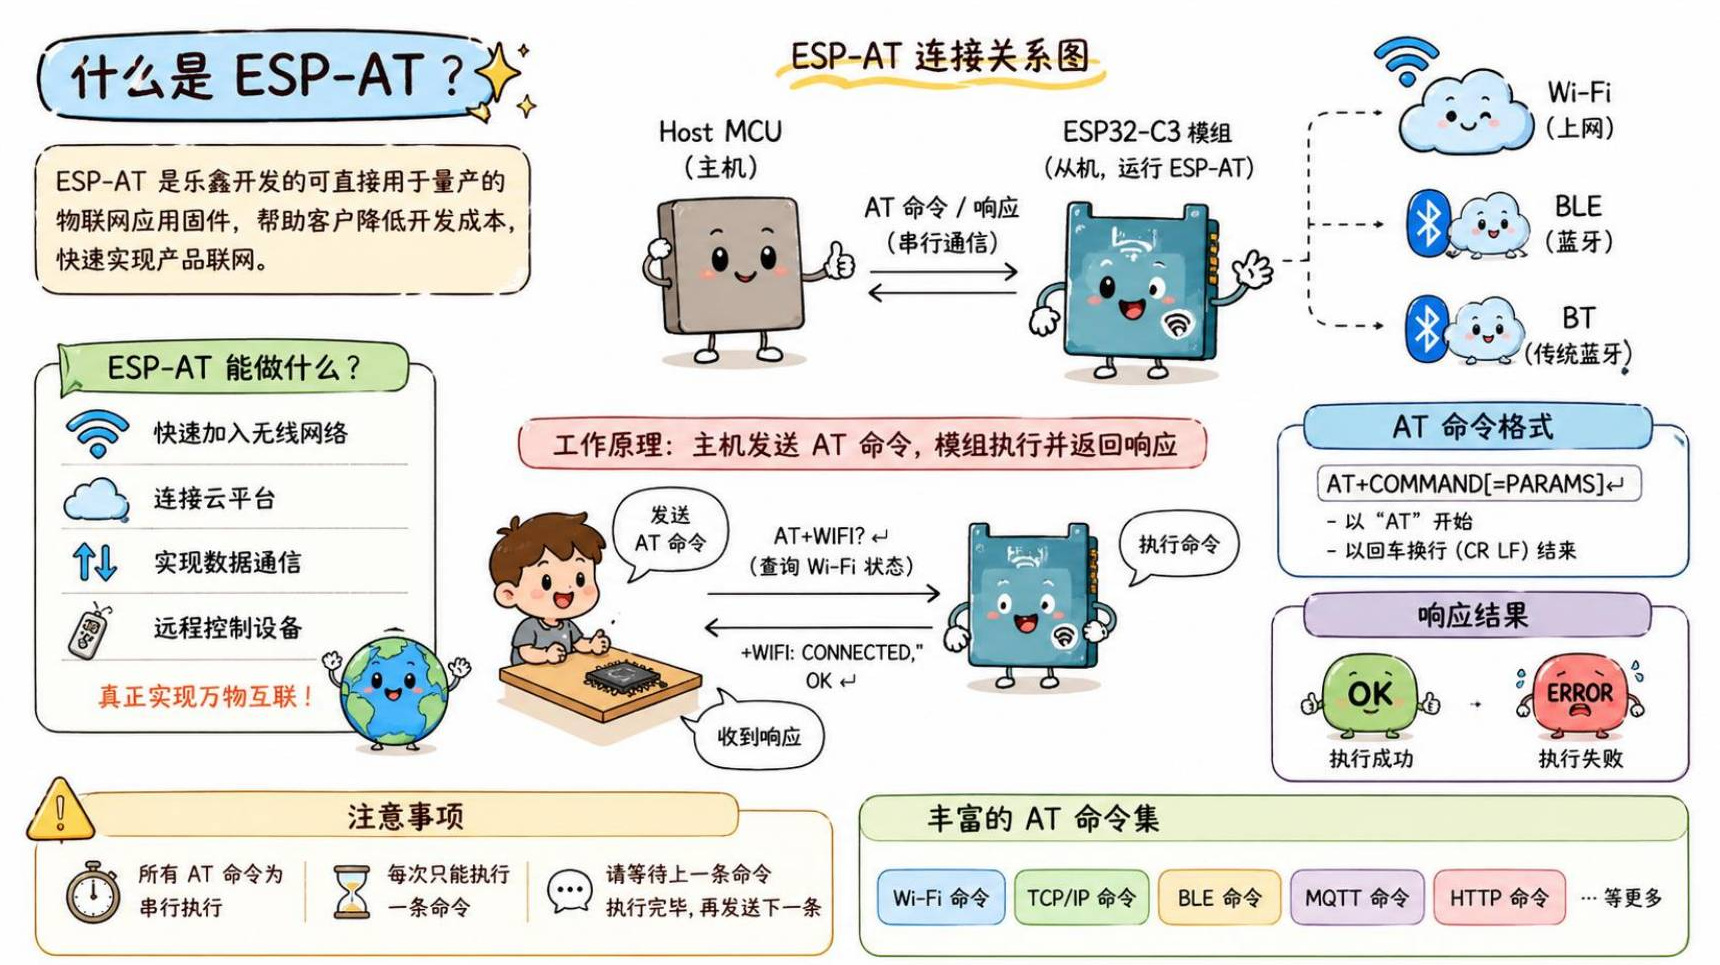

*讲义第55页：主控发送命令，ESP模组执行并返回响应。图为ESP-AT概念介绍，示例气泡不代表C3支持全部功能。*

ESP-AT是乐鑫提供的物联网通信固件。烧入ESP32-C3后，模块负责Wi-Fi及网络协议；主控通过UART发送命令字符串，就能请求扫描热点、连接路由器或发送HTTP请求。这样，GD32可以把联网部分交给通信模块处理。

```text
PC或GD32主控  ← UART命令/响应 →  ESP32-C3运行ESP-AT  ← Wi-Fi → 路由器 → 网络服务
```

例如，发送 `AT` 做接口测试；发送 `AT+CWMODE?` 查询Wi-Fi模式。模块会返回数据行和 `OK` 或 `ERROR` 等结果。命令是一条条串行执行的：应等待本条命令的终态响应，再发下一条；连接和HTTP操作还可能同时产生异步状态消息。

命令一般以 `AT` 开头，并以回车换行 `\r\n` 结束。`?` 通常用于查询，`=参数` 用于设置。`ATE0/ATE1` 是特殊格式，不带 `+` 和等号。

讲义概念图画有传统蓝牙，但**ESP32-C3支持BLE，不支持Bluetooth Classic**。本篇只操作Wi-Fi、SmartConfig、PING与HTTP命令；不要把概念插图当成特定芯片的完整功能表。


## 3. 两个串口：下载日志与AT命令分开

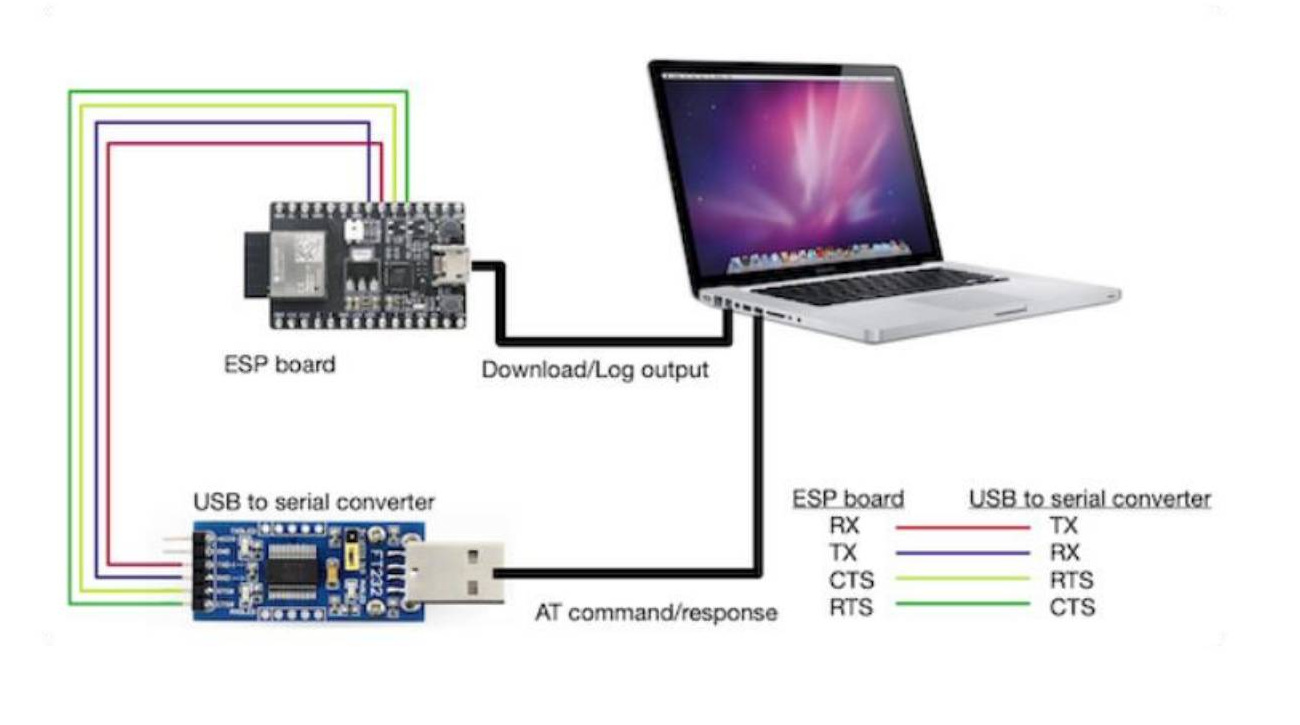

*讲义第56页：板载USB用于下载固件和查看启动日志；独立USB转UART模块用于发送AT命令、接收响应。*

本课默认ESP32-C3-MINI-1 AT固件使用两个UART：

| 用途 | ESP32-C3默认管脚 | 对端 | 用途说明 |
|---|---|---|---|
| UART0 RX | GPIO20 | 下载端TX → GPIO20 | 下载固件 |
| UART0 TX | GPIO21 | 下载端RX ← GPIO21 | 查看启动日志 |
| UART1 RX | GPIO6 | USB-TTL TX → GPIO6 | 接收AT命令 |
| UART1 TX | GPIO7 | USB-TTL RX ← GPIO7 | 输出AT响应 |
| 共地 | GND | USB-TTL GND ↔ 开发板GND | 串口通信参考地 |
| UART1 CTS/RTS | GPIO5 / GPIO4 | 对接RTS/CTS | 仅硬件流控时需要 |

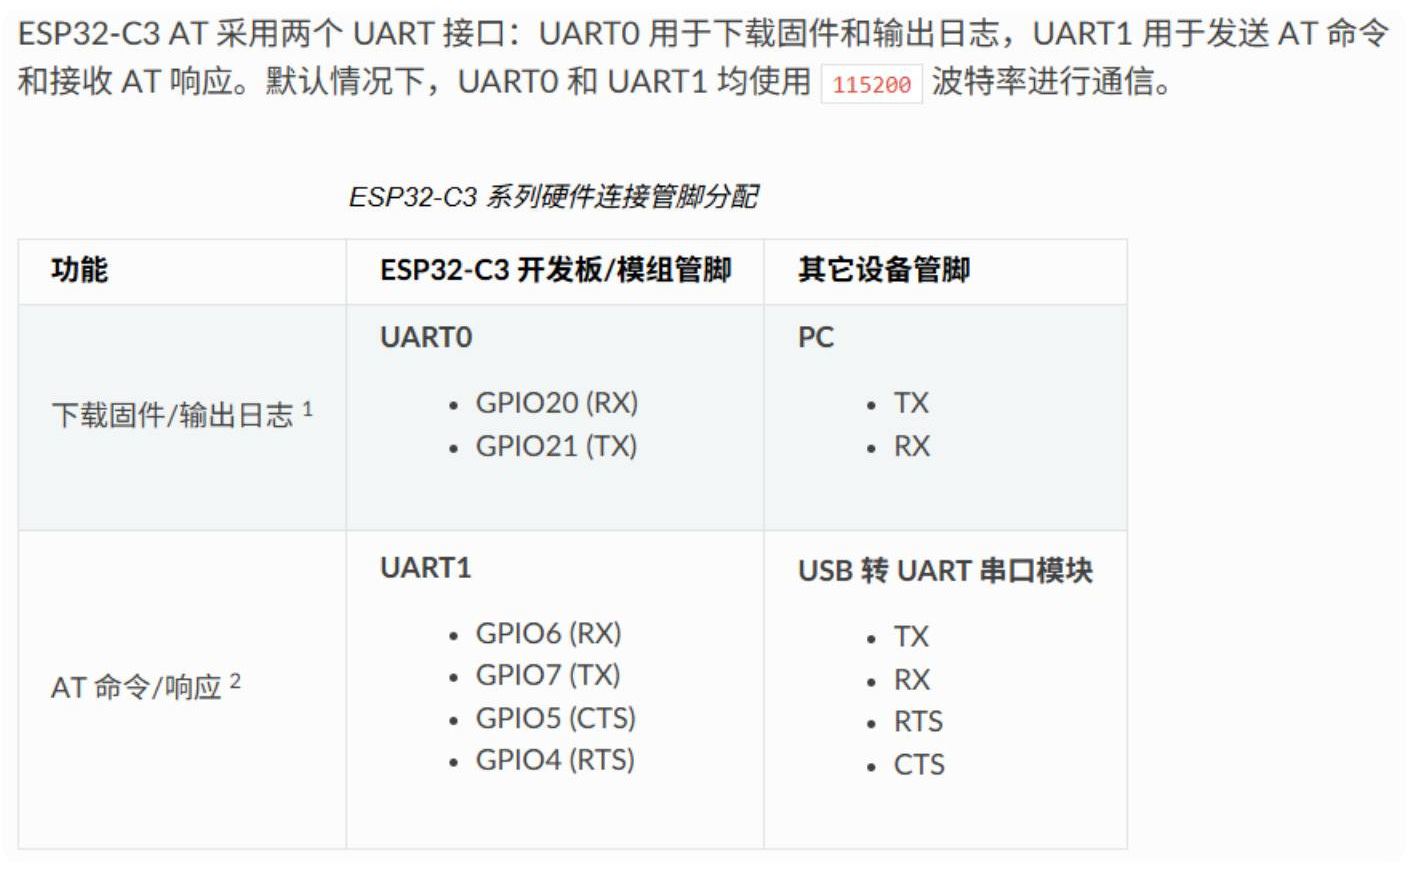

*讲义第57页：课程固件的默认UART引脚；两路UART默认115200波特率。定制固件可能改管脚。*

视频23的命令测试只接 **TX、RX、GND** 三根线。开发板已通过自身USB供电时，不要再随意从USB-TTL供电脚反向供电。确认USB-TTL的逻辑电平适配ESP32-C3的3.3V UART。

两个串口可能显示成两个不同COM口。烧录用板载下载口；发AT命令时要打开连接GPIO6/7的USB-TTL端口。**在日志口看到启动信息，不能证明AT口已接通。**实际开发板、模组和固件管脚若与课程板不同，应查各自原理图和配置。


## 4. 选择课程固件：ESP32-C3-MINI-1 AT V4.1.1.0

课程资料提供ESP-AT固件包和Flash Download Tool。对应官方同名包解压后可看到：

```text
ESP32-C3-MINI-1-AT-V4.1.1.0/
  [ESP32C3-AT][v4.1.1.0]用户指南.pdf
  ESP32-C3-MINI-1-AT-V4.1.1.0/
    download.config
    factory/
      factory_MINI-1.bin
      factory_MINI-1_unfilled.bin
    bootloader/
    partition_table/
    customized_partitions/
    esp-at.bin
```

`factory_MINI-1.bin`是4 MiB的合并量产固件，烧录到Flash地址 `0x0`。视频选用 `factory` 目录中的合并文件。不要把单独的 `esp-at.bin` 当成完整factory固件直接烧到 `0x0`。

**同包新格式补充：**`factory_MINI-1_unfilled.bin`约2.09 MiB，是官方指南优先推荐的较小合并文件，也烧到 `0x0`。课程复现可按视频使用 `factory_MINI-1.bin`；也可依随包指南选用unfilled版本，切勿把两个文件的适用地址混淆。

包内 `download.config`列出多文件烧录的芯片参数和地址，例如DIO、40 MHz、4 MB，以及各分区bin对应的地址。那是按分区逐项烧录的另一种方式；本课先用一个factory合并文件，不把它与逐分区写法混用。不同芯片或Flash容量需要匹配相应固件包，不能只凭文件名含ESP32-C3就认定兼容。


## 5. Windows烧录：factory合并文件写入0x0

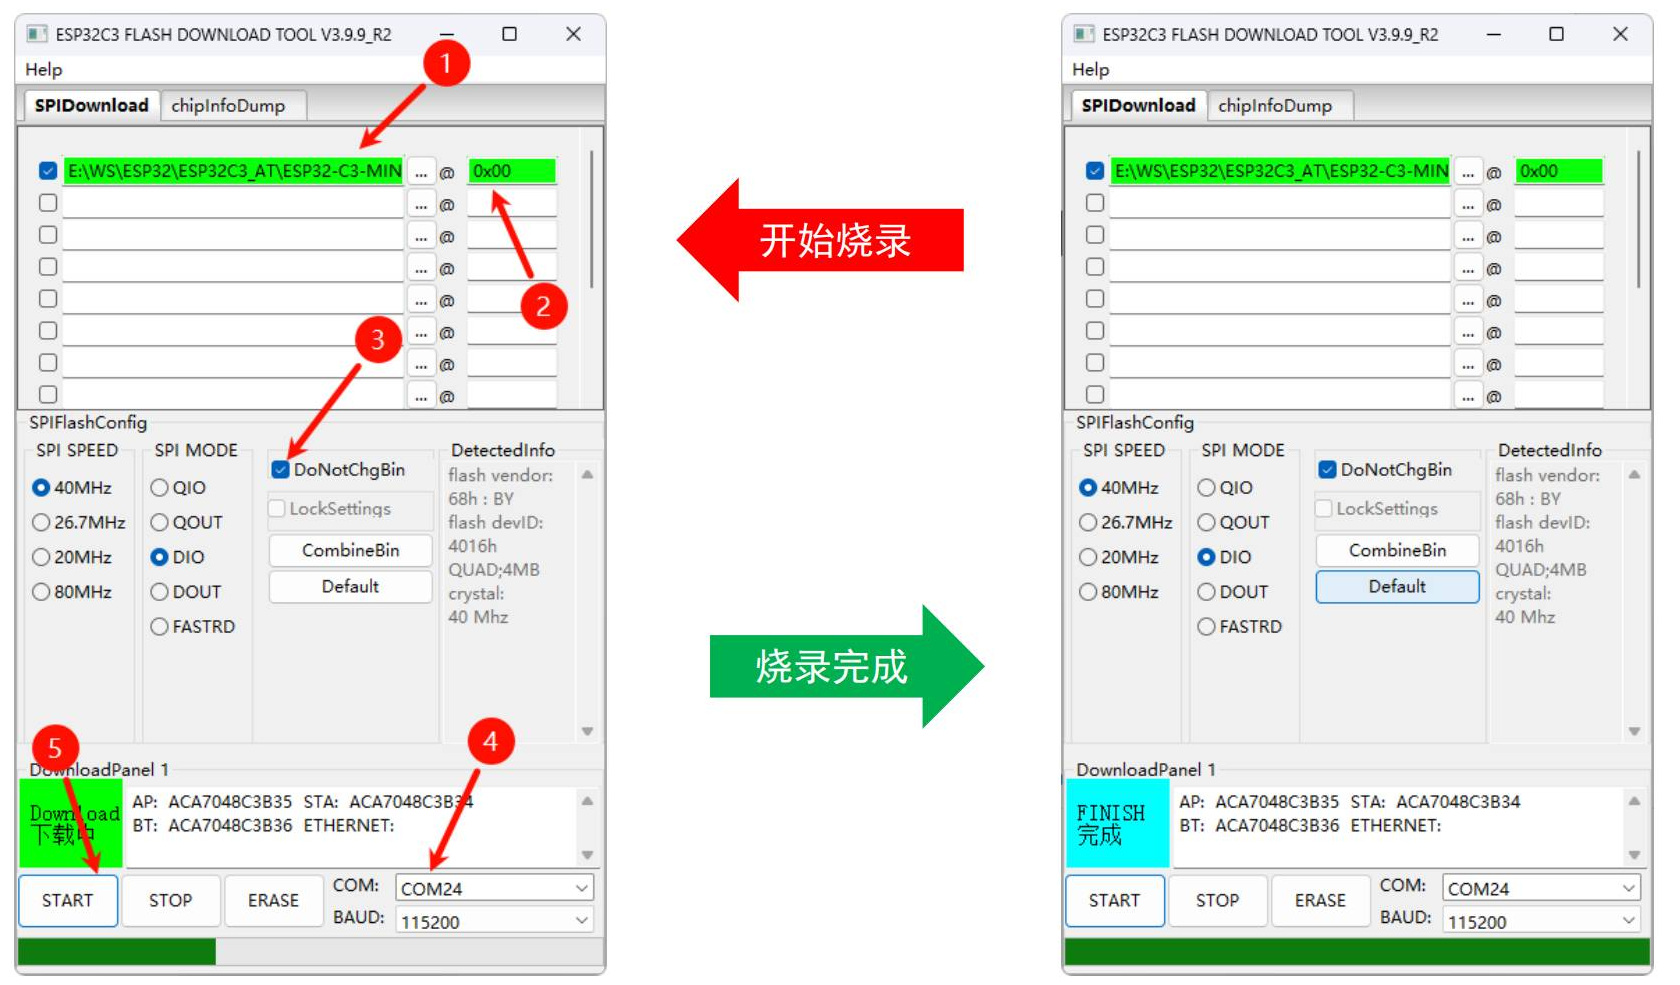

*讲义第59页截图为Flash Download Tool V3.9.9_R2：勾选factory文件、地址0x00、DoNotChgBin、COM和波特率。课程视频所用工具版本界面略有不同。*

按课程操作：

1. 开发板用可传输数据的USB线接PC。确认设备管理器里出现对应下载串口。
2. 打开Flash Download Tool，芯片选 **ESP32-C3**。如工具要求工作模式和接口，按官方指南选开发/串口烧录模式。
3. 在第一行选择 `factory/factory_MINI-1.bin`，**勾选该行**，地址填 **`0x0`**（界面显示`0x00`含义相同）。
4. 使用合并固件时按课程勾选 **DoNotChgBin**，保留文件内的Flash参数。新版工具识别合并固件后可能自动锁定部分参数，属于界面差异。
5. 选开发板下载口对应的COM与`115200`波特率。视频里的COM号只属于讲师电脑。
6. 点击 **START**，不要中途拔线，等待工具显示 **FINISH/完成**。
7. 关闭烧录工具，复位开发板，再用GPIO6/7对应的USB-TTL串口做AT握手。

烧录成功分两层：工具显示FINISH说明下载流程完成；AT口发送 `AT` 得到 `OK`，再用 `AT+GMR` 读到预期版本，才能确认AT固件已运行并可通信。若下载一直等待，先检查COM口、串口占用、数据线和该板是否需要BOOT/RESET进入下载模式。本课所用板子的操作不代表所有C3板都自动进入下载模式。


## 6. 串口参数与AT基础命令

给USB-TTL对应的AT端口设置：

| 参数 | 课程配置 |
|---|---|
| 波特率 | 115200 |
| 数据位、校验、停止位 | 8、None、1 |
| 流控 | None；本课不接CTS/RTS |
| 发送 | 文本/ASCII |
| 行结束 | CR LF，即字节0D 0A |

开发板启动后，UART1通常会输出 `ready`。先逐条发送：

```text
AT
AT+GMR
```

AT返回OK表示基础通信通了；GMR用于查看AT版本。课程指定固件为V4.1.1.0，完整编译日期和SDK版本应以本机实际响应为准，不应抄用其他人的输出。

视频中的基础命令：

| 命令 | 作用 | 注意 |
|---|---|---|
| `AT` | 测试命令/响应 | 用于串口握手 |
| `AT+GMR` | 查询版本 | 烧录后核对固件 |
| `AT+CMD?` | 查询支持的命令及类型 | 要带问号 |
| `ATE0` | 关闭命令回显 | 仍会返回OK和结果 |
| `ATE1` | 开启命令回显 | 发送内容会原样显示 |
| `AT+RST` | 软件复位 | 等待重新启动和ready |
| `AT+RESTORE` | 恢复出厂设置并重启 | 会擦除保存的配置 |

视频23演示SSCOM扩展按钮和命令配置文件，可选配，非必需。复制配置后仍应改成自己的COM并检查CRLF设置。课程也切换到串口调试助手显示中文；工具换了，UART参数和AT命令规则不变。


## 7. 命令结束符与回显：最常见的两类误判

发送一条普通命令时，模块需要收到完整的回车换行：

```text
字符：A  T  CR LF
十六进制：41 54 0D 0A
```

串口工具可勾选“发送新行/CRLF”。若关闭该选项，模块可能一直等行结束符。视频23实际演示过：首次没返回，打开回车换行后又把未完成字符带入下一条，导致接收内容混乱；应等当前响应结束，再重新发送完整命令。

在C代码字符串里，`\r\n`会生成两个控制字符：

```c
const char command[] = "AT\r\n";
/* UART发送 sizeof(command) - 1 个字节，不发送末尾的'\0' */
```

串口输入框中直接打出反斜杠字母 `\r\n`，不一定会被工具翻译成CRLF；优先使用工具明确的换行设置。

回显与命令响应也要区分。`ATE0`只关闭模块把收到的命令原样回显，并不关闭 `OK`、`ERROR`、查询结果或联网状态通知。视频中软件复位后回显重新出现，故主控在启动握手后可再次执行 `ATE0`，不要假定设置跨复位保留。

`AT+CMD?`查询当前固件支持的命令集合。若输入 `AT+CMD` 报错，首先核对是否漏写问号。命令列表只说明该固件支持哪些AT命令；具体参数、可查询/可设置能力仍要查对应命令文档。

每次只发一条，等它执行结束。Wi-Fi连接、SmartConfig和HTTP比AT握手耗时长，不能因一时没有即时返回就连续堆发多条命令。


## 8. 复位、恢复出厂与断开热点不是一回事

| 操作 | 命令/方式 | 主要效果 |
|---|---|---|
| 硬件复位 | 开发板RESET，或按板卡设计控制EN | 重新启动并加载已保存配置 |
| 软件复位 | `AT+RST` | 重启模块，通常保留保存的配置 |
| 恢复出厂 | `AT+RESTORE` | 擦除保存到Flash的参数并重启 |
| 断开当前AP | `AT+CWQAP` | 断开Wi-Fi连接，不等于擦除所有历史配置 |

模块可能保存连接过的热点并在重启后自动重连；`AT+RESTORE`会清除保存的热点设置。官方还提供 `AT+SYSSTORE`控制参数保存模式：`AT+SYSSTORE=1`表示将受该设置控制的配置保存到Flash，`AT+SYSSTORE=0`表示不保存。视频中某次重启后自动连接属于那次设备状态，不能推成所有固件的普遍行为。

视频24为准备SmartConfig调用了恢复出厂命令。正常断网或测试HTTP，不需要每次都恢复出厂。清理后应重新查询当前模式并从头配置。


## 9. Wi-Fi模式与手动连接

查询模式：

```text
AT+CWMODE?
```

| 返回值 | 模式 | 角色 |
|---|---|---|
| 0 | 无Wi-Fi模式 | 关闭Wi-Fi射频 |
| 1 | Station / STA | 作为客户端连入路由器 |
| 2 | SoftAP | 模块自己提供热点 |
| 3 | SoftAP + Station | 同时提供热点并连接路由器 |

视频24当时查询到模式2，模块释放自己的热点；设置为1后再去连接其他Wi-Fi。本课网络请求和SmartConfig使用Station模式：

```text
AT+CWMODE=1
AT+CWLAP
```

每条之间等到OK或扫描结束。CWLAP扫描周围热点；若仍在SoftAP模式，不能照着Station扫描结果预期操作。

连接命令示例：

```text
AT+CWJAP="WIFI_IOT","3.1415926"
```

`WIFI_IOT`及密码是讲义示例值，不是通用热点信息。复现时换成自己的SSID和密码。ESP32-C3使用2.4 GHz Wi-Fi，不支持5 GHz Wi-Fi；手机可以用蜂窝网络上网，同时提供兼容的2.4 GHz热点，这与“5G蜂窝网络”不是一个概念。

成功时常见顺序：

```text
WIFI CONNECTED
WIFI GOT IP
OK
```

`WIFI CONNECTED`表示关联到AP，`WIFI GOT IP`表示获得IP。连接完成后再查：

```text
AT+CWJAP?
AT+CIPSTA?
AT+CIFSR
```

`AT+CIPSTA?`是查询Station地址的完整语法；`AT+CIFSR`可查询有效接口的IP/MAC。视频24曾报告CIPSTA命令测试不顺并改用CIFSR，讲义也有简写，但官方命令格式包含问号。不能以一次失败断定命令不支持；先核对命令结尾、连接状态和固件版本。没有硬件复测，故这里只给出校正后的格式。


## 10. 分层检查网络：IP、PING和断开

查询到Station IP后，可用PING验证路由和域名：

```text
AT+PING="www.baidu.com"
```

视频中讲师的设备当时约13 ms返回成功；该时延只代表那次课堂网络。超时可能是DNS、目标服务、网络策略或链路问题，单次PING超时并不能证明HTTP一定不可用。

主动断开当前AP：

```text
AT+CWQAP
```

视频接着观察到PING超时、Station地址无效；重新执行CWJAP并等待获取IP后才能继续联网。建议按以下层级定位：

```text
AT串口是否收发正常
  → CWMODE是否含Station
  → 目标热点是否为2.4 GHz且连接成功
  → Station是否获得IP
  → 域名解析/目标网络服务是否可达
```

有私网IP只证明AP分配了本地地址，不代表该网络一定能访问公网。


## 11. SmartConfig：手机协助提供Wi-Fi配置

手动执行 `AT+CWJAP="SSID","PASSWORD"`适合研发验证，不适合作为普通用户配网流程。SmartConfig让设备进入监听状态，手机选择目标2.4 GHz热点并提交配网信息，ESP32-C3获取SSID/密码后再连接路由器。

```text
用户让设备进入配网状态
  → 手机连接目标2.4 GHz Wi-Fi并提交配网信息
  → ESP32-C3接收信息并尝试连接路由器
  → 模块获得IP并通知手机/主控
```

SmartConfig不是路由器主动把密码给设备，而是手机按设备支持的配网协议发送信息。课程重点演示ESP-TOUCH与AirKiss兼容方式：

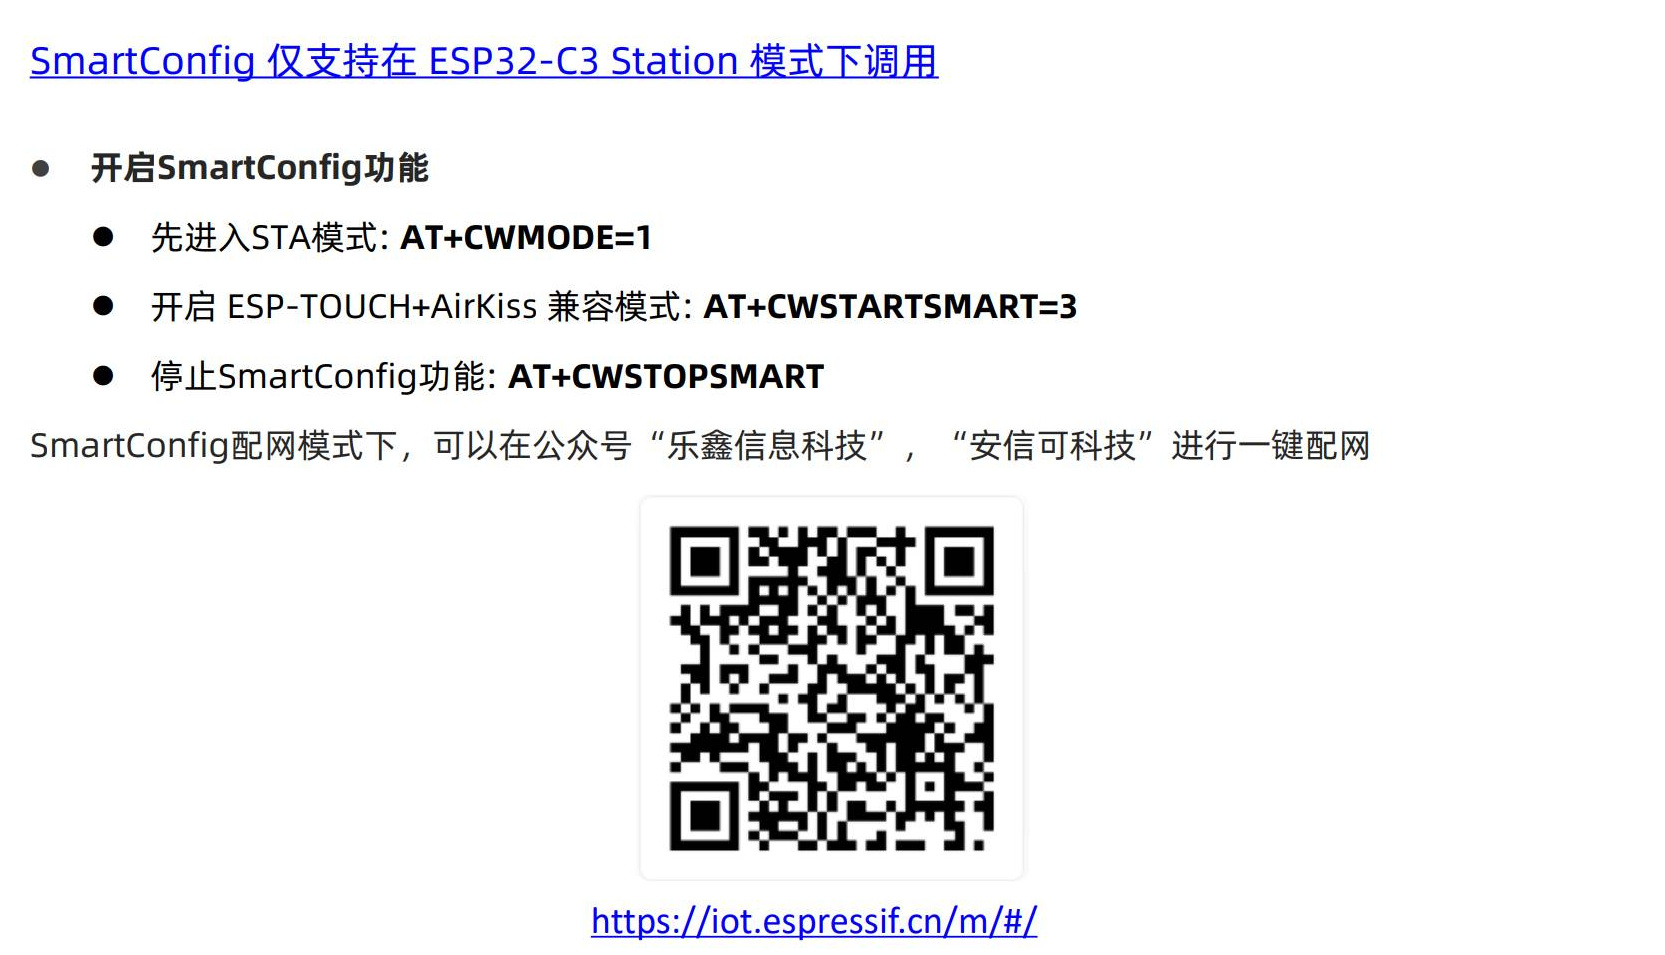

*讲义第62页：仅在ESP32-C3 Station模式调用；先设置CWMODE=1，再CWSTARTSMART=3，完成后CWSTOPSMART。*

设备端逐条执行：

```text
AT+CWMODE=1
AT+CWSTARTSMART=3
```

type参数包括1 ESP-TOUCH、2 AirKiss、3 两种兼容、4 ESP-TOUCH v2。本课选3。第二条返回OK只表示SmartConfig已启动，不表示已经连上网络。

手机端使用与协议类型匹配的配网入口，选目标2.4 GHz Wi-Fi并输入密码；设备已进入等待后，再点击手机端开始配网。视频里的二维码/公众号入口可能随服务变化，关键在于手机端与模块端协议要匹配。

**重要的收尾步骤：**课程口述提到“配置完不用手动停止”，但本课同版本随包指南和官方文档要求在结束后执行 `AT+CWSTOPSMART`，释放其占用内存；成功通知后建议等待超过6秒，使结果先同步到手机。配网过程中不要发送其他AT命令。失败或取消时也要结束当前SmartConfig后再启动下一轮。

`CWSTOPSMART`停止配网监听，**不等同于 `CWQAP`断开已经建立的Wi-Fi**。后续顺序为：等待配网完成 → 等待建议的同步时间 → CWSTOPSMART → 查询AP/IP → 执行业务命令。


## 12. 其他配网方式与SmartConfig时序

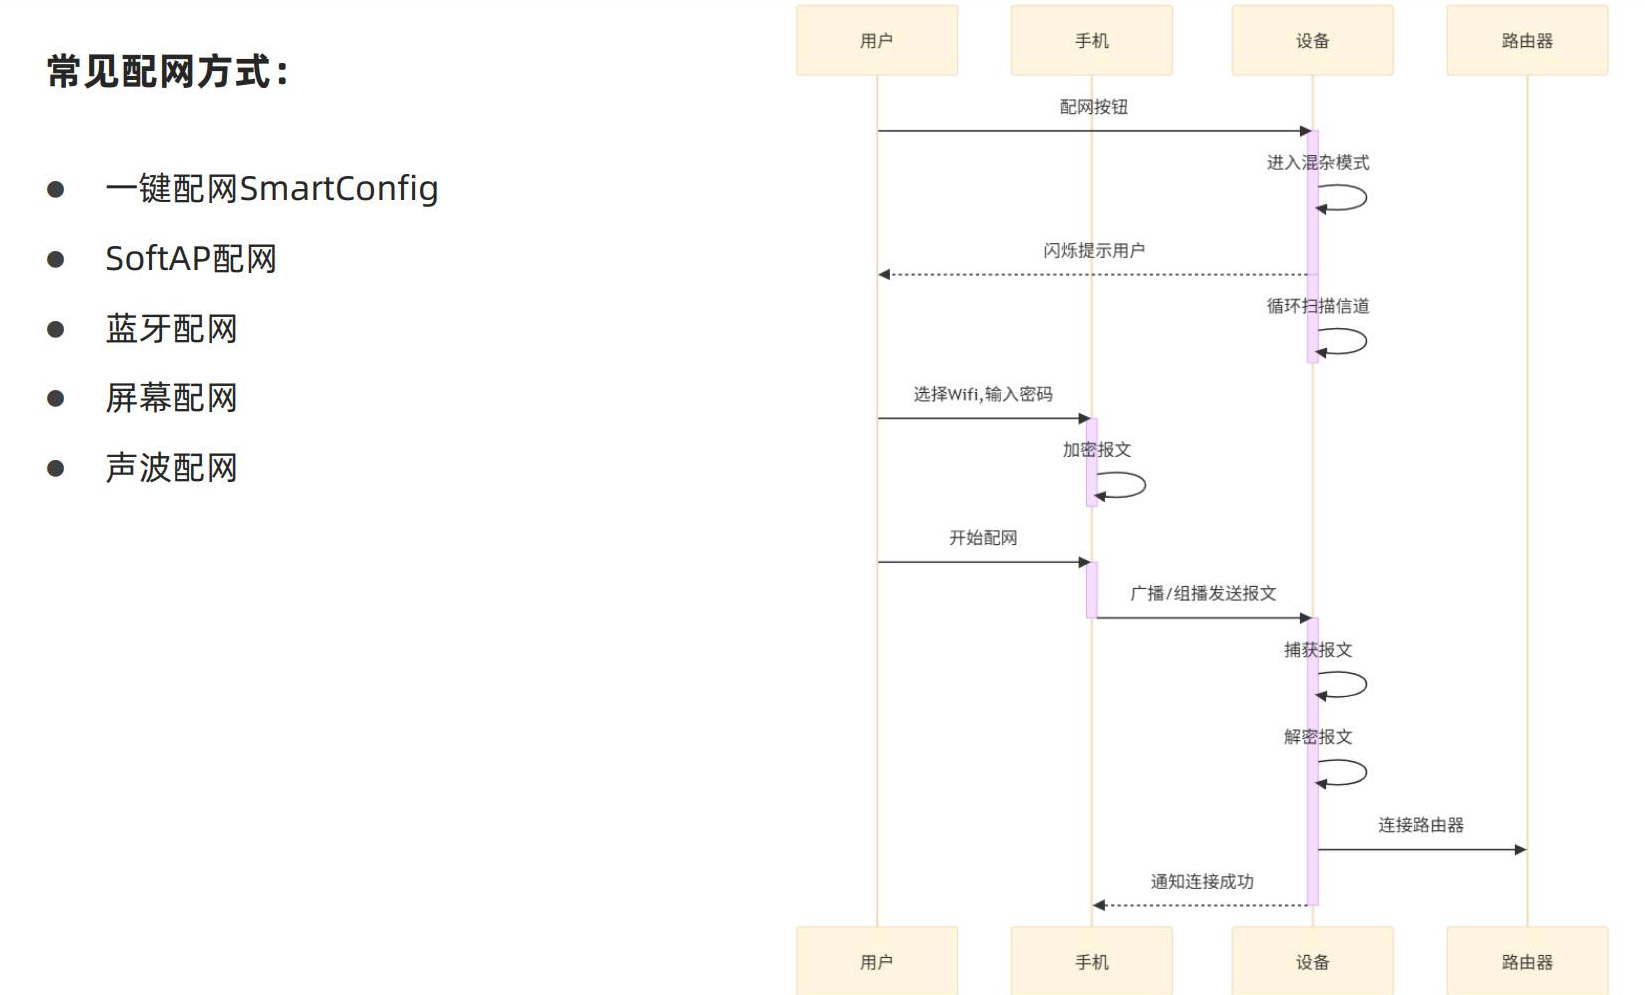

*讲义第63页：设备接收手机传来的信息后连接路由器；左侧也列出其他配网方案。*

| 方案 | 配置信息如何到设备 | 典型条件 |
|---|---|---|
| SmartConfig | 手机通过兼容协议发送，模块监听接收 | 2.4 GHz、手机端与设备协议匹配 |
| SoftAP配网 | 手机连接设备热点，通过应用/页面提交配置 | 手机需切换当前连接的热点 |
| 蓝牙配网 | 手机用BLE发送热点配置 | 芯片、固件和应用都支持 |
| 屏幕配网 | 用户在设备屏幕上选网、输入信息 | 设备有屏幕及交互输入 |
| 声波配网 | 手机播放编码信号，设备收听解析 | 设备具备麦克风及对应协议 |

课程把SmartConfig作为一键配网例子。真正产品需按硬件、用户体验及安全要求选择；本篇没有实现SoftAP、BLE或声波配网。配网本身会传递家庭网络凭据，产品开发应采用可信的配置渠道和合理的数据保护措施。


## 13. HTTPCLIENT参数：GET请求与回显

确认ESP32-C3已经连接Wi-Fi并获得IP，且SmartConfig已结束，再发送HTTP命令。本课基本语法：

```text
AT+HTTPCLIENT=<opt>,<content-type>,"url","host","path",<transport_type>[,"data"][,"http_req_header"]...
```

尖括号、方括号仅用于说明语法，不是要输入的字符。课程GET示例：

```text
AT+HTTPCLIENT=2,0,"http://httpbin.org/get","","",1
```

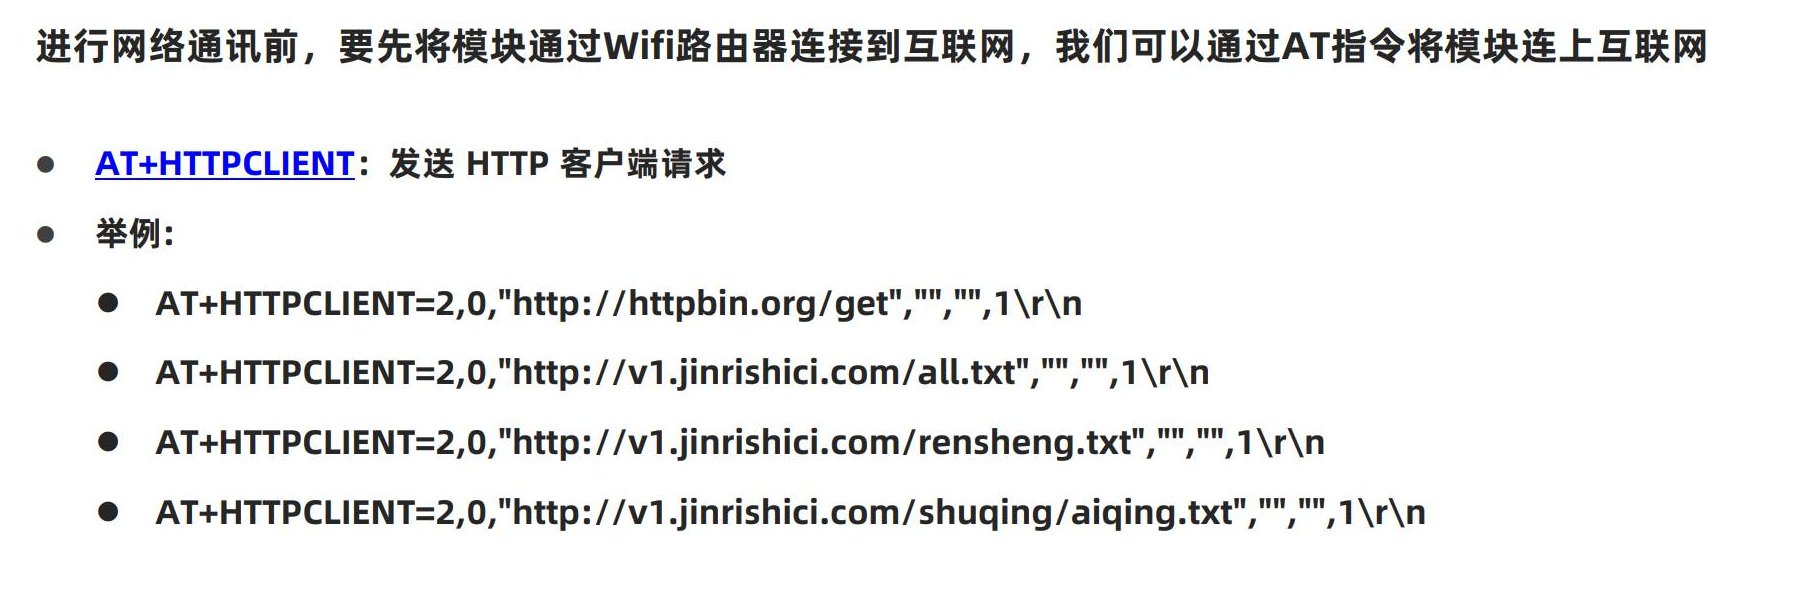

*讲义第64页：连接互联网后使用HTTPCLIENT，展示httpbin和今日诗词等GET示例。*

| 参数 | 示例 | 含义 |
|---|---|---|
| opt | 2 | 请求方式：1 HEAD、2 GET、3 POST、4 PUT、5 DELETE |
| content-type | 0 | 请求数据类型：0表单、1 JSON、2 multipart、3 XML |
| url | 完整URL | 非空时由URL确定主机和路径 |
| host/path | 两个空字符串 | 使用完整URL时留空占位 |
| transport_type | 1 | HTTP over TCP；2表示SSL/TLS传输 |
| data | 此GET省略 | 仅POST方法使用 |
| 请求头 | 此GET省略 | 可在data规则之后提供 |

URL非空时host/path被忽略，但空字符串的位置要保留。`content-type`描述请求载荷类型，不是串口工具的字符显示编码。HTTPS另涉及TLS配置、证书与服务端要求，本篇没有验证HTTPS。

视频GET响应来自httpbin，服务器会回显URL和请求头。响应常见为 `+HTTPCLIENT:<size>,<data>` 后接 `OK`。size按**字节**计，数据可能分多段返回，不能假定整份JSON恰好一次到达。

今日诗词是课程外部服务示例；接口可用性可能变化，失败时区分命令语法、网络、DNS、HTTP重定向和服务更新。官方说明HTTPCLIENT不自动跟随301/302重定向，部分固件也可能未编入HTTP命令。


## 14. 中文乱码：字符显示编码与接收字节长度

视频26请求中文诗句时出现乱码，随后在串口调试助手里把字符集调整为UTF-8后可正常显示。这说明英文正常、中文错误时，先检查**返回字节使用的编码**与**工具显示编码**是否一致；不应立即去改波特率。

课堂按“27字节约9个汉字”说明UTF-8字符长度。那只是该例中每个汉字占3字节的情况，不代表所有UTF-8字符都固定3字节；ASCII字符通常1字节，其他字符也可能不同。HTTP封装里的size是字节，不是可见字符数。

```text
显示正常 ≠ 串口载荷可按字符个数计长
UTF-8中文    → 先按收到的字节拼完整，再按UTF-8解析
固件bin文件  → 按二进制长度接收，不做UTF-8/GBK转换
```

**工程补充：**网络响应可能分段，GD32应先按长度累计字节，再交给文本或二进制处理层。将来下载固件时不能用strlen判断二进制长度，也不能让字符集转换碰固件数据。


## 15. 请求头和POST表单：位置随请求方式变化

请求头格式是 `Key: value`；表单字段格式是 `key=value&key2=value2`，属于不同层次。

GET没有data参数，因此transport_type后面的字符串可作为请求头：

```text
AT+HTTPCLIENT=2,0,"http://httpbin.org/get","","",1,"X-Lab-Tag: demo"
```

视频26曾尝试给GET增加data，后发现非POST请求里data位置不存在，尾部内容会按请求头解释。若要设置多个头，可按命令语法提供多个请求头字符串。上面的 `X-Lab-Tag`是教学示例。

POST表单示例：

```text
AT+HTTPCLIENT=3,0,"http://httpbin.org/post","","",1,"field1=value1&field2=value2"
```

这里 `opt=3`表示POST，`content-type=0`表示表单，最后的字符串才是data；服务器返回JSON应能在form字段看到两组键值。课程视频演示了该结果。

POST还需要请求头时，把它们放在data之后：

```text
AT+HTTPCLIENT=3,0,"http://httpbin.org/post","","",1,"field1=value1&field2=value2","X-Lab-Tag: demo"
```

具体AT固件对URL、命令总长度和HTTP支持有边界；官方文档建议长URL改用HTTPURLCFG，较长POST可用HTTPCPOST，更多请求头可参考HTTPCHEAD。产品接口的路径、鉴权头和内容格式必须看服务端API，不能拿课程示例头当真实平台凭据。


## 16. 一次完整复现清单

请逐条发送命令，等待响应后再进入下一步；不要把所有命令粘成一条批量发送。

**路径A：手动连接热点。**

| 顺序 | 命令/操作 | 通过条件 |
|---|---|---|
| 1 | 烧录factory固件到0x0并复位 | 下载工具显示完成，模块启动 |
| 2 | 在GPIO6/7对应串口发送AT | 返回OK |
| 3 | AT+GMR | 版本符合预期 |
| 4 | ATE0 | 回显关闭，结果仍正常返回 |
| 5 | AT+CWMODE=1 | 返回OK |
| 6 | AT+CWLAP | 目标2.4 GHz热点可见 |
| 7 | AT+CWJAP="YOUR_SSID","YOUR_PASSWORD" | 连接并获得IP |
| 8 | AT+CWJAP?、AT+CIPSTA?、AT+CIFSR | 核对AP和本机地址 |
| 9 | AT+PING="www.baidu.com" | 记录实际返回结果 |
| 10 | HTTPCLIENT GET | 收到HTTP数据和最终响应 |
| 11 | HTTPCLIENT POST表单 | 响应中能核对提交字段 |

`YOUR_SSID`和`YOUR_PASSWORD`为占位符，替换为实际热点参数；记录或分享实验笔记时不应公开真实密码。

**路径B：SmartConfig后联网。**

```text
AT → GMR → ATE0 → CWMODE=1
→ CWSTARTSMART=3
→ 手机连接目标2.4 GHz Wi-Fi并发起配网
→ 等待设备取得热点信息、连接并获得IP
→ 按指南等待手机同步时间
→ CWSTOPSMART
→ 查询AP/IP
→ HTTP GET或POST
```

`CWSTARTSMART`返回OK仅表示进入配网流程，不等于已经联网。路径结束条件应基于连接、IP和HTTP响应逐层确认。恢复出厂不是每次联网必做项；仅在需要清理历史配置时使用，之后重新检查启动状态和模式。


## 17. 常见问题定位

| 现象 | 优先检查 |
|---|---|
| 烧录工具等不到设备 | 下载COM、USB数据线、端口占用、该板是否需手动进下载模式 |
| 板载日志正常但AT无响应 | AT端口是否为USB-TTL；TX→GPIO6、RX←GPIO7、共地 |
| 发送AT没有返回 | 115200/8N1、文本发送、CRLF是否实际送出 |
| 连续命令结果混在一起 | 是否等到上条命令终态；处理中不能连发 |
| AT+CMD报错 | 查询命令是否写为AT+CMD? |
| 关回显后还有OK | ATE0只关命令原样回传，不关响应 |
| 扫不到热点 | 先设Station；确认2.4 GHz、信号及SSID |
| 连上但没法请求 | 是否已收到IP；再分别查DNS、外网和目标HTTP服务 |
| CIPSTA失败 | 查询格式应为AT+CIPSTA?；可另用AT+CIFSR核对有效接口 |
| SmartConfig启动报错 | 是否已先设Station，旧配网是否已CWSTOPSMART |
| 配网后其他命令异常 | 等手机同步，按指南调用CWSTOPSMART释放资源 |
| 中文乱码但英文正常 | 检查串口工具显示字符集；常见需UTF-8 |
| GET参数位置错 | 非POST没有data参数；尾部字段可能被当请求头 |
| POST的form为空 | 核对opt=3、content-type=0、data和键值格式 |
| HTTP返回过长/分段 | 按字节长度累积响应，不假定一行/一包是完整JSON |
| HTTP请求错误 | 查命令拼写、当前固件支持、网络状态、URL和重定向 |

这是排查顺序，不是单一原因诊断表。保留实际AT收发内容，每次只改变一个条件，才容易定位问题。


## 18. 从手动命令过渡到GD32主控

本节是工程补充，不是视频22—26给出的一套可直接编译的GD32驱动。PC手动操作将来由主控程序接管：

| 人工步骤 | GD32侧责任 |
|---|---|
| 输入AT并等待OK | UART握手、命令队列、超时和错误处理 |
| 看见WIFI GOT IP | 接收并解析异步网络状态 |
| 点击手机配网 | 维护配网状态和同步等待 |
| 复制HTTP命令 | 按接口生成参数并检查转义与长度 |
| 看诗句或JSON | 将AT响应与HTTP载荷分层处理 |
| 看见文件下载完成 | 另行校验长度、完整性并安排Flash写入 |

必须区分“命令已接受”和“业务已完成”：SmartConfig启动返回OK不等于连接成功，HTTP有响应不等于GD32 App已升级。HTTP响应和固件二进制也应按字节长度收取，解析逻辑不能依赖一包完整到达。

ESP32-C3负责无线连接与网络请求；GD32仍负责升级决策、固件校验、Flash写入和启动控制。OneNET升级任务、下载固件、分段接收和状态上报留到后续笔记，本篇不声称已实现这些步骤。


## 19. 本篇复习与资料索引

| 自测问题 | 要点 |
|---|---|
| 开发板USB能烧录但AT不通，首先看什么？ | 下载/日志是UART0；AT默认UART1在GPIO6/7 |
| AT串口最少接几根线？ | TX/RX交叉、GND共地 |
| factory合并固件烧到哪？ | 0x0；不要混用分区bin |
| AT命令怎样结束？ | CR LF，即0D 0A |
| ATE0会关闭响应吗？ | 不会，只关闭命令回显 |
| Station与SoftAP有何区别？ | Station连路由器，SoftAP提供热点 |
| 查询CIPSTA的命令完整形式？ | AT+CIPSTA? |
| SmartConfig返回OK是否代表成功连网？ | 不是；继续等待连接/IP状态并按指南CWSTOPSMART |
| HTTPCLIENT里opt=2是什么？ | GET；data只用于POST |
| 请求头和表单怎么区分？ | 请求头Key: value；表单key=value&key2=value2 |
| 谁真正发起HTTP请求？ | ESP32-C3；PC/GD32通过UART控制和接收 |
| HTTP能通是否等于OTA完成？ | 不是，升级还需下载、校验、Flash写入和启动 |

**课程资料：**视频22—26，讲义物理页54—64，Resource/WIFI-OTA固件包及烧录工具。

**乐鑫官方参考：**[AT固件发布页](https://docs.espressif.com/projects/esp-at/zh_CN/latest/esp32c3/AT_Binary_Lists/esp_at_binaries.html)、[硬件连接](https://docs.espressif.com/projects/esp-at/zh_CN/latest/esp32c3/Get_Started/Hardware_connection.html)、[烧录指导](https://docs.espressif.com/projects/esp-at/zh_CN/latest/esp32c3/Get_Started/Downloading_guide.html)、[基础AT命令](https://docs.espressif.com/projects/esp-at/zh_CN/latest/esp32c3/AT_Command_Set/Basic_AT_Commands.html)、[Wi-Fi与SmartConfig](https://docs.espressif.com/projects/esp-at/zh_CN/latest/esp32c3/AT_Command_Set/Wi-Fi_AT_Commands.html)、[TCP/IP命令](https://docs.espressif.com/projects/esp-at/zh_CN/latest/esp32c3/AT_Command_Set/TCP-IP_AT_Commands.html)、[HTTP命令](https://docs.espressif.com/projects/esp-at/zh_CN/latest/esp32c3/AT_Command_Set/HTTP_AT_Commands.html)。

在线latest文档可能更新；课程复现以实际AT+GMR、对应模组固件和配套用户指南为准。本篇特别核对了课程版本的factory文件、SmartConfig停止步骤和HTTPCLIENT参数差异。
